# 🌐 Live Web App (Cloud Deployment)

**Deployment link:** `PASTE-YOUR-STREAMLIT-LINK-HERE` (e.g. `https://diamond-price-predictor.streamlit.app`)

> The trained model (`diamond_price_model.pkl`) is served by a Streamlit web app (`web_app/app.py`) deployed on **Streamlit Community Cloud**. Step 13 at the end of this notebook explains how it was deployed.

# Diamond Price Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses (including **XGBoost**).

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. **Step 2.1** downloads the full dataset (`diamonds.csv`, 53,940 diamonds) automatically from GitHub. If Colab has no internet access, a **"Choose Files"** button appears instead. Click it and select `diamonds.csv` from your computer.

---

## Introduction

##### **Definition** A regression ML task that predicts the price (in US dollars) of a diamond from its physical and quality characteristics: carat (weight), cut, colour, clarity, depth, table and its three dimensions.
##### **Application** Online jewellery stores, diamond wholesalers, insurance valuation, pawn shops, resale marketplaces and customers who want to check whether a quoted price is fair.

### Why This Problem Is Similar to Car Price Prediction

| | Car Price Prediction | Diamond Price Prediction |
|---|---|---|
| **Task type** | Regression | Regression |
| **Output** | Price of a car (MSRP, $) | Price of a diamond ($) |
| **Input** | Mix of numeric (HP, year, MPG) and categorical (style, category) features | Mix of numeric (carat, depth, x, y, z) and categorical (cut, colour, clarity) features |
| **Evaluation** | RMSE with K-Fold CV | RMSE with K-Fold CV |
| **Full dataset size** | 11,914 cars | **53,940 diamonds** (≈ 4.5× larger) |

### Aim of This Notebook

> **Which of 5 regression algorithms predicts diamond prices best, and how sure can we be about that answer?**

As instructed, the 5 algorithms used here are **different from the 5 used in the Car Price Prediction System** (Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting are **not** used).

### What is K-Fold Cross Validation?

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** score over the K rounds (and the standard deviation).

With **K = 10** on the **full dataset (~53,800 unique diamonds)**, each test fold has about 5,380 diamonds and each training set has about 48,400 diamonds.

### Evaluation Measure: Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ = actual price, $\hat{y}_i$ = predicted price, $n$ = number of test diamonds
- RMSE is in **US dollars**: *"on average, predictions are off by about $X"*.
- **Lower RMSE = better model.**

## Input and Output

### Input (Features / Attributes)

| Feature | Description | Type | Possible Values |
|---|---|---|---|
| **carat** | Weight of the diamond | Numerical | 0.2 – 5.01 |
| **cut** | Quality of the cut | Categorical (ordered) | Fair < Good < Very Good < Premium < Ideal |
| **color** | Diamond colour | Categorical (ordered) | J (worst) < I < H < G < F < E < D (best) |
| **clarity** | How clear the diamond is | Categorical (ordered) | I1 (worst) < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF (best) |
| **depth** | Total depth percentage = z / mean(x, y) | Numerical | 43 – 79 |
| **table** | Width of the top of the diamond relative to its widest point (%) | Numerical | 43 – 95 |
| **x** | Length in mm | Numerical | 0 – 10.74 |
| **y** | Width in mm | Numerical | 0 – 58.9 |
| **z** | Depth in mm | Numerical | 0 – 31.8 |

### Output (Prediction)

| Output Attribute | Description | Data Type |
|---|---|---|
| **price** | Price of the diamond in US dollars | Numerical |

### Example Records

| carat | cut | color | clarity | depth | table | x | y | z | price |
|---|---|---|---|---|---|---|---|---|---|
| 0.23 | Ideal | E | SI2 | 61.5 | 55 | 3.95 | 3.98 | 2.43 | 326 |
| 0.21 | Premium | E | SI1 | 59.8 | 61 | 3.89 | 3.84 | 2.31 | 326 |
| 0.29 | Premium | I | VS2 | 62.4 | 58 | 4.20 | 4.23 | 2.63 | 334 |

## Developer & System Information

| **Attribute** | **Details** |
|---|---|
| **Developer Name** | *[Your Name]* – *[Registration No.]* |
| **Course** | Machine Learning Fundamentals (AIC354), Fall 2026 |
| **Program Name** | `diamond_price_kfold_full_dataset_10fold` |
| **IDE** | Google Colab |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, scikit-learn, XGBoost, Matplotlib, tqdm, Pickle (built-in) |
| **Dataset** | `diamonds.csv` (53,940 diamonds, 10 attributes). Source: [seaborn-data on GitHub](https://github.com/mwaskom/seaborn-data/blob/master/diamonds.csv) (the classic *Diamonds* dataset, also on Kaggle) |
| **Deployment** | Streamlit web app on Streamlit Community Cloud (`web_app/app.py`) |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load the Full Dataset
- **Step 3:** Understand and Pre-process the Data
- **Step 4:** Feature Extraction
- **Step 5:** Build the Pre-processing Pipeline
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms
- **Step 10:** Train and Save the Final Model (accuracy + deployability)
- **Step 11:** Execute the Application Phase
- **Step 12:** Execute the Feedback Phase
- **Step 13:** Model Deployment (Cloud + Web App)
- **Conclusion**

# Code – Diamond Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python Libraries ---
import os
import pickle
import time
import urllib.request

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

# --- The 5 Regression Algorithms (none of them used in the Car Price system) ---
from sklearn.linear_model import Ridge
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
import xgboost
from xgboost import XGBRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  XGBoost      : {xgboost.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.2.5
  Pandas       : 2.3.3
  scikit-learn : 1.7.0
  XGBoost      : 2.1.4
  Matplotlib   : 3.8.4


# Step 2: Load the Full Dataset
## Step 2.1: Download the Dataset

The notebook downloads the **full** dataset from GitHub. If the download fails (no internet), it asks you to upload `diamonds.csv` instead. If the file is already present, nothing is downloaded.

In [2]:
DATA_FILE = "diamonds.csv"
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"

# google.colab is only available inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(DATA_FILE):
    try:
        print(f"Downloading the full dataset from {DATA_URL} ...")
        urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    except Exception as error:
        print(f"Download failed ({error}).")
        if IN_COLAB:
            print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
            uploaded = files.upload()
            uploaded_name = list(uploaded.keys())[0]
            if uploaded_name != DATA_FILE:
                os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again.")

'diamonds.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the diamonds in the dataset.

In [3]:
diamonds = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {diamonds.shape[0]:,} diamonds, {diamonds.shape[1]} attributes")

diamonds.head()

Loaded dataset: 53,940 diamonds, 10 attributes


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


# Step 3: Understand and Pre-process the Data
## Step 3.1: Understand the Data

In [4]:
print("\nAttributes in the Data:")
print("=======================\n")
print(list(diamonds.columns))

print("\nNumber of Instances:")
print("====================\n")
print(len(diamonds))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = diamonds.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

print("\nDiamonds with an impossible size (x, y or z = 0 mm):")
print("====================================================\n")
print(((diamonds[["x", "y", "z"]] == 0).any(axis=1)).sum())


Attributes in the Data:

['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Number of Instances:

53940

Missing Values in Each Attribute:

No missing values

Diamonds with an impossible size (x, y or z = 0 mm):

20


### Understanding the Output (price)

Diamond prices are **skewed**: most diamonds cost under $5,500, but large, high-quality stones cost up to about $18,800.

In [5]:
price_summary = diamonds["price"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
price_summary.to_frame(name="price ($)")

,price ($)
count,"53,940.00"
mean,"3,932.80"
std,"3,989.44"
min,326.00
25%,950.00
50%,"2,401.00"
75%,"5,324.25"
95%,"13,107.10"
99%,"17,378.22"
max,"18,823.00"


> **Why this matters for RMSE:** RMSE squares each error, so mistakes on expensive diamonds raise the RMSE much more than mistakes on cheap ones. Unlike the car dataset, however, there are **no extreme outliers** (the most expensive diamond is ~58× the cheapest; in the car data it was ~1,000×), so we expect RMSE to be much smaller *relative to the average price*.

## Step 3.2: Pre-process the Data

In [6]:
"""
Pre-processing steps:
---------------------
1. Remove duplicate rows. A duplicate could land in BOTH the training folds and the
   test fold, so the model would be tested on a diamond it has already seen.
2. Remove diamonds whose length, width or depth is 0 mm. These are data-entry errors:
   a real diamond cannot have a size of zero.
3. There are no missing values, but an imputer is still kept inside the pipeline
   (Step 5) so the deployed model can safely handle an empty field.
"""

rows_before = len(diamonds)
diamonds = diamonds.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed       : {rows_before - len(diamonds):,}")

rows_before = len(diamonds)
diamonds = diamonds[(diamonds[["x", "y", "z"]] > 0).all(axis=1)].reset_index(drop=True)
print(f"Zero-size diamonds removed   : {rows_before - len(diamonds):,}")
print(f"Instances remaining          : {len(diamonds):,}")

Duplicate rows removed       : 146
Zero-size diamonds removed   : 19
Instances remaining          : 53,775


# Step 4: Feature Extraction

We use **all 9 input features**. Then we separate the **input (X)** from the **output (y)**.

In [7]:
numeric_features = ["carat", "depth", "table", "x", "y", "z"]
categorical_features = ["cut", "color", "clarity"]
target = "price"

X = diamonds[numeric_features + categorical_features]
y = diamonds[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of diamonds: {len(X):,}")

X.head()

Input features (X): 9 columns -> ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut', 'color', 'clarity']
Output (y)        : price
Number of diamonds: 53,775


,carat,depth,table,x,y,z,cut,color,clarity
0,0.23,61.50,55.00,3.95,3.98,2.43,Ideal,E,SI2
1,0.21,59.80,61.00,3.89,3.84,2.31,Premium,E,SI1
2,0.23,56.90,65.00,4.05,4.07,2.31,Good,E,VS1
3,0.29,62.40,58.00,4.20,4.23,2.63,Premium,I,VS2
4,0.31,63.30,58.00,4.34,4.35,2.75,Good,J,SI2


# Step 5: Build the Pre-processing Pipeline

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | Ridge Regression and the Neural Network are sensitive to feature scale |
| Categorical | **Ordinal encoding with the real quality order** | Cut, colour and clarity have a *natural order* (e.g. *Fair < Good < … < Ideal*). Encoding them as 0, 1, 2, … keeps that order and adds only 3 columns |

> **Difference from the Car Price system:** there, *Vehicle Style* (Sedan, Coupe, …) has **no** order, so one-hot encoding was the right choice. Here the categories are **quality grades**, so ordinal encoding is the better choice.

As in the Car Price notebook, the pre-processing is placed **inside the pipeline**, so in every round of cross validation it is fitted on the **training folds only** (no data leakage).

In [8]:
cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=[cut_order, color_order, clarity_order],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


# Step 6: Define the 5 Regression Algorithms

None of these algorithms was used in the Car Price Prediction System:

| # | Algorithm | Family | How it predicts a price |
|---|---|---|---|
| 1 | **Ridge Regression** | Regularised linear model | Like Linear Regression, but adds a penalty on large weights (L2 regularisation), which makes it more stable when features are correlated (carat, x, y and z are strongly correlated) |
| 2 | **AdaBoost** | Boosting (adaptive re-weighting) | Trains 50 small trees one after another; each new tree pays **more attention to the diamonds the previous trees got most wrong** (re-weights the samples), then combines them by a weighted median |
| 3 | **Extra Trees** (Extremely Randomised Trees) | Bagging-style ensemble | Builds 100 trees, but unlike Random Forest it uses the **whole** training set for each tree and picks split thresholds **at random**. The extra randomness reduces variance and makes training faster |
| 4 | **Neural Network (MLP)** | Deep learning | A multi-layer perceptron with two hidden layers (64 and 32 neurons, ReLU). It learns non-linear combinations of the features using back-propagation |
| 5 | **XGBoost** | Regularised gradient boosting (separate library) | Builds trees sequentially using **second-order (Newton) gradients**, L1/L2 regularisation of leaf weights and histogram-based splitting. It is a different algorithm and library from scikit-learn's `GradientBoostingRegressor` |

**Settings:** default settings are used wherever possible so the comparison stays simple and fair. Two small practical choices for the Neural Network: *early stopping* (stop when the validation error stops improving) and scaling the **target** price to mean 0 / std 1 during training (`TransformedTargetRegressor`). Neural networks train poorly on raw targets in the thousands; the predictions are converted back to dollars automatically. `random_state=42` makes the results reproducible.

In [9]:
algorithms = {
    "Ridge Regression": Ridge(alpha=1.0),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Neural Network (MLP)": TransformedTargetRegressor(
        regressor=MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                               max_iter=500, random_state=42),
        transformer=StandardScaler(),
    ),
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. AdaBoost
  3. Extra Trees
  4. Neural Network (MLP)
  5. XGBoost


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: the dataset is sorted by price, so without shuffling a fold could contain only cheap diamonds
- `random_state=42`: the **same folds are used for all 5 algorithms**, which makes the comparison fair

In [10]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

In [11]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Diamonds": len(train_index),
        "Testing Diamonds": len(test_index),
        "Avg Price of Test Diamonds ($)": y.iloc[test_index].mean(),
        "Most Expensive Test Diamond ($)": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Diamonds,Testing Diamonds,Avg Price of Test Diamonds ($),Most Expensive Test Diamond ($)
Fold (Round),,,,
1,48397,5378,"3,888.82",18818
2,48397,5378,"3,980.47",18804
3,48397,5378,"3,874.70",18791
4,48397,5378,"3,943.26",18781
5,48397,5378,"3,857.46",18823
6,48398,5377,"3,901.44",18803
7,48398,5377,"3,915.72",18787
8,48398,5377,"4,055.48",18795
9,48398,5377,"3,863.18",18784


Because the data were shuffled, every fold has a very similar average price, so the folds are fair tests.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds, we:

1. make a **fresh copy** of the pipeline (`clone`),
2. **train** it on the 9 training folds,
3. **predict** the prices of the diamonds in the test fold,
4. calculate the **RMSE** for that fold.

The `tqdm` progress bar has **5 × 10 = 50 steps** and shows the elapsed time and the estimated remaining time.

> ⏱ **This step takes a few minutes in Colab.** Extra Trees is the slowest algorithm because it grows 100 full-depth trees on ~48,000 diamonds in every round.

In [12]:
fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time taken for all folds

folds = list(kfold.split(X))     # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<22} -> mean RMSE = ${fold_rmse[name].mean():>9,.2f}   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

Done: 100%|##########| 50/50 [11:37<00:00, 13.96s/fold]


Ridge Regression       -> mean RMSE = $ 1,228.35   (2.4 s)
AdaBoost               -> mean RMSE = $ 1,173.53   (47.0 s)
Extra Trees            -> mean RMSE = $   533.54   (234.1 s)
Neural Network (MLP)   -> mean RMSE = $   571.31   (406.1 s)
XGBoost                -> mean RMSE = $   538.27   (8.2 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

In [13]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"
per_fold_table.to_csv("per_fold_rmse.csv")

(per_fold_table.style
    .format("${:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,AdaBoost,Extra Trees,Neural Network (MLP),XGBoost
Fold,,,,,
Fold 1,"$1,188","$1,159",$536,$571,$537
Fold 2,"$1,236","$1,182",$516,$560,$512
Fold 3,"$1,225","$1,130",$534,$561,$529
Fold 4,"$1,223","$1,194",$535,$555,$546
Fold 5,"$1,226","$1,222",$543,$559,$542
Fold 6,"$1,227","$1,164",$524,$559,$529
Fold 7,"$1,206","$1,162",$504,$526,$522
Fold 8,"$1,194","$1,160",$541,$578,$547
Fold 9,"$1,306","$1,211",$546,$664,$559


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds: the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds (small = consistent) |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Price** | Mean RMSE divided by the average diamond price |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [14]:
average_price = y.mean()

summary = pd.DataFrame({
    "Mean RMSE ($)": per_fold_table.mean(),
    "Std RMSE ($)": per_fold_table.std(),
    "Best Fold RMSE ($)": per_fold_table.min(),
    "Worst Fold RMSE ($)": per_fold_table.max(),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"
summary.to_csv("summary_comparison.csv")

print(f"Average diamond price in this data: ${average_price:,.2f}\n")

money_columns = ["Mean RMSE ($)", "Std RMSE ($)", "Best Fold RMSE ($)", "Worst Fold RMSE ($)"]
(summary.style
    .format({**{c: "${:,.0f}" for c in money_columns},
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE ($)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average diamond price in this data: $3,931.22



,Rank,Mean RMSE ($),Std RMSE ($),Best Fold RMSE ($),Worst Fold RMSE ($),RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,
Extra Trees,1,$534,$15,$504,$557,13.6%,234.09
XGBoost,2,$538,$15,$512,$560,13.7%,8.20
Neural Network (MLP),3,$571,$36,$526,$664,14.5%,406.07
AdaBoost,4,"$1,174",$28,"$1,130","$1,222",29.9%,47.03
Ridge Regression,5,"$1,228",$33,"$1,188","$1,306",31.2%,2.40


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better), with a whisker of ± 1 standard deviation.
**Chart 2** shows the RMSE of **every individual fold** as a dot.

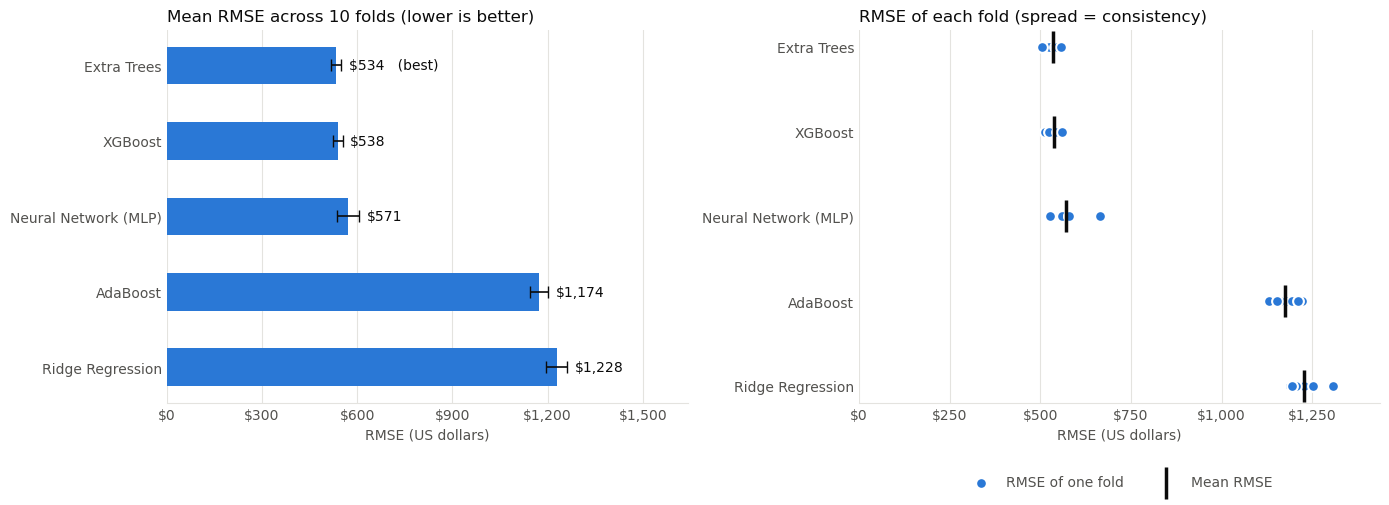

In [15]:
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

means = summary["Mean RMSE ($)"]
stds = summary["Std RMSE ($)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"${means[name]:,.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)

for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.savefig("algorithm_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9.4: Observations

> The numbers below come from our run. With different library versions the numbers may differ slightly, but the overall pattern should be the same.

1. **Extra Trees has the lowest mean RMSE ($534)**, with **XGBoost** second ($538). The difference ($5) is smaller than their standard deviation (≈ $15), so the two are practically **tied**. Extra Trees won 7 of the 10 folds and XGBoost won 3.
2. **Non-linear models clearly win.** Extra Trees, XGBoost, Neural Network (MLP) all stay at or below $571, while AdaBoost ($1,174) and Ridge Regression ($1,228) have about **double** the error. Diamond price grows non-linearly with carat (a 2-carat diamond costs far more than two 1-carat diamonds), which a weighted sum of features cannot capture. AdaBoost uses only 50 shallow trees (depth 3), so it underfits.
3. **The results are very consistent.** The standard deviation across folds is only $15–$36. In the car notebook the standard deviation was almost as large as the mean. Here every test fold has about 5,380 diamonds and there are no extreme outliers (the most expensive diamond in every fold is about $18,800).
4. **The best error is about 13.6% of the average price**, compared with 36.6% for the best car model. The 4 Cs (carat, cut, colour, clarity) and the size of a diamond determine its price much more directly than car specifications determine a car's price.
5. **Accuracy vs. speed:** XGBoost was about **29× faster** than Extra Trees (8 s vs 234 s for all 10 folds). The Neural Network was the slowest algorithm (406 s) and was not more accurate.
6. **Deployability matters (Step 10):** the Extra Trees model file is about **604 MB** because it stores 100 full-depth trees, while the XGBoost file is only **0.44 MB**.

# Step 10: Train and Save the Final Model
## Step 10.1: Selection Rule

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The model will be **deployed to the cloud**, so we use two criteria:

1. **Accuracy:** prefer the algorithm with the **lowest mean RMSE** (Step 9.2).
2. **Deployability:** the saved model file must be **smaller than 100 MB**. The web app is deployed from GitHub, and GitHub rejects files larger than 100 MB. A huge model file is also slow to load in a web app.

Tree ensembles that grow **full-depth trees** (such as Extra Trees) store every leaf of every tree, so on ~54,000 diamonds their file can be hundreds of MB. Boosting models with shallow trees (XGBoost) and neural networks are tiny by comparison.

## Step 10.2: Train on All the Data, Save, and Check the File Size

We go down the ranking (best RMSE first). Each algorithm is trained on **all** the diamonds and saved. The **first one whose file is under 100 MB** becomes the final model. The saved file contains the **whole pipeline** (imputer, scaler, ordinal encoder **and** the algorithm), so the web app can predict directly from raw diamond characteristics.

In [16]:
MODEL_FILE = "diamond_price_model.pkl"
MAX_MODEL_MB = 100
DOWNLOAD_MODEL = False     # set True to download the model file in Colab

for candidate_name in summary.index:                     # best mean RMSE first
    final_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", clone(algorithms[candidate_name])),
    ])
    final_model.fit(X, y)                                 # train on ALL diamonds

    model_bundle = {
        "model": final_model,
        "algorithm": candidate_name,
        "cv_rmse": float(summary.loc[candidate_name, "Mean RMSE ($)"]),
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "cut_order": cut_order,
        "color_order": color_order,
        "clarity_order": clarity_order,
    }
    with open(MODEL_FILE, "wb") as f:
        pickle.dump(model_bundle, f)

    size_mb = os.path.getsize(MODEL_FILE) / 1e6
    fits = size_mb <= MAX_MODEL_MB
    print(f"{candidate_name:<22} mean RMSE ${model_bundle['cv_rmse']:>6,.0f}   "
          f"model file {size_mb:>8,.2f} MB  ->  {'SELECTED' if fits else 'too large to deploy'}")
    if fits:
        break
    del final_model, model_bundle                         # free memory before the next candidate

best_algorithm_name = candidate_name
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE ($)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE ($)"]

print(f"\nFinal model    : {best_algorithm_name} (trained on {len(X):,} diamonds)")
print(f"Expected RMSE  : ${best_mean_rmse:,.2f} (+/- ${best_std_rmse:,.2f})")
print(f"Saved as       : '{MODEL_FILE}' ({size_mb:.2f} MB)")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)

Extra Trees            mean RMSE $   534   model file   604.47 MB  ->  too large to deploy
XGBoost                mean RMSE $   538   model file     0.44 MB  ->  SELECTED

Final model    : XGBoost (trained on 53,775 diamonds)
Expected RMSE  : $538.27 (+/- $15.46)
Saved as       : 'diamond_price_model.pkl' (0.44 MB)


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example diamond below, so that **Run all** works without stopping. Set `USE_INTERACTIVE_INPUT = True` to type in your own diamond.

In [17]:
USE_INTERACTIVE_INPUT = False

example_diamond = {
    "carat": 1.0,
    "depth": 61.8,
    "table": 57.0,
    "x": 6.40,
    "y": 6.43,
    "z": 3.97,
    "cut": "Ideal",
    "color": "G",
    "clarity": "VS1",
}

def get_diamond_input():
    print("Enter Diamond Characteristics:")
    diamond = {
        "carat": float(input(f"Carat ({X['carat'].min()} - {X['carat'].max()}): ")),
        "depth": float(input("Depth % (e.g. 61.8): ")),
        "table": float(input("Table % (e.g. 57): ")),
        "x": float(input("Length x in mm: ")),
        "y": float(input("Width y in mm: ")),
        "z": float(input("Depth z in mm: ")),
    }
    diamond["cut"] = input(f"Cut {cut_order}: ").strip()
    diamond["color"] = input(f"Color {color_order}: ").strip().upper()
    diamond["clarity"] = input(f"Clarity {clarity_order}: ").strip().upper()
    return diamond

user_input = get_diamond_input() if USE_INTERACTIVE_INPUT else example_diamond

print("Diamond characteristics:")
for feature, value in user_input.items():
    print(f"  {feature:<8}: {value}")

Diamond characteristics:
  carat   : 1.0
  depth   : 61.8
  table   : 57.0
  x       : 6.4
  y       : 6.43
  z       : 3.97
  cut     : Ideal
  color   : G
  clarity : VS1


## Step 11.2: Convert User Input into Feature Vector

In [18]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,carat,depth,table,x,y,z,cut,color,clarity
0,1.00,61.80,57.00,6.40,6.43,3.97,Ideal,G,VS1


## Step 11.3: Load the Saved Model

In [19]:
with open(MODEL_FILE, "rb") as f:
    loaded_bundle = pickle.load(f)
loaded_model = loaded_bundle["model"]

print(f"Model loaded from '{MODEL_FILE}': {loaded_bundle['algorithm']}")

Model loaded from 'diamond_price_model.pkl': XGBoost


## Step 11.4: Model Prediction

In [20]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price: ${predicted_price:,.2f}")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about ${best_mean_rmse:,.0f}")

Predicted Price: $6,987.99
Typical error (cross-validation RMSE of XGBoost): about $538


# Step 12: Execute the Feedback Phase

Potential improvements based on feedback from users and domain experts (jewellers, gemologists):

1. **Tune hyper-parameters** with cross validation (`GridSearchCV` / `RandomizedSearchCV`), e.g. the learning rate, depth and number of trees in XGBoost, or the network size in the MLP.
2. **Add certification features**: fluorescence, polish, symmetry and the grading lab (GIA, IGI) also affect price but are not in this dataset.
3. **Collect current market data**: the dataset reflects older prices; diamond prices change with the market.
4. **Report MAE and MAPE** alongside RMSE, since a $500 error matters much more on a $600 diamond than on a $15,000 one.

# Step 13: Model Deployment (Cloud + Web App)

The saved model was deployed as a **Streamlit web app** on **Streamlit Community Cloud** (free).

| File | Purpose |
|---|---|
| `web_app/app.py` | Streamlit web app: a form for the 9 diamond characteristics and a **Predict Price** button |
| `web_app/diamond_price_model.pkl` | The trained pipeline saved in Step 10.2 |
| `web_app/requirements.txt` | Library versions the cloud server installs |

**Deployment steps**

1. Create a public GitHub repository and upload the three files in the `web_app` folder.
2. Go to **https://share.streamlit.io**, sign in with GitHub and click **Create app**.
3. Select the repository, branch `main` and main file `app.py`, then click **Deploy**.
4. After 1–2 minutes the app is live at a public `https://<name>.streamlit.app` URL. That link is written at the very top of this notebook.

# Conclusion

In this notebook we compared **5 regression algorithms not used in the Car Price system** (Ridge Regression, AdaBoost, Extra Trees, Neural Network and XGBoost) on the **full diamonds dataset (53,775 unique diamonds)** using **10-fold cross validation** and **RMSE**.

- **Extra Trees ($534) and XGBoost ($538) are tied** for accuracy, with the Neural Network next ($571). Ridge Regression and AdaBoost are about twice as bad because diamond prices are strongly non-linear.
- **XGBoost was selected as the final model:** it is as accurate as Extra Trees (within one standard deviation), about 29× faster to train, and its model file is 0.44 MB instead of about 604 MB, so it can be deployed from GitHub.
- The final pipeline was trained on all 53,775 diamonds, saved with pickle, used to predict the price of a new diamond ($6,987.99), and **deployed as a Streamlit web app**.
- **Compared with the car price system**, the diamond results are both more accurate (best RMSE ≈ 13.6% of the average price vs 36.6%) and far more reliable (std ≈ $15 vs $13,116), thanks to the larger dataset and the absence of extreme outliers.

### Comparison With the Car Price System

| | Car Price (full data, 10-fold) | Diamond Price (full data, 10-fold) |
|---|---|---|
| Instances | 11,199 | 53,775 |
| Best mean RMSE | $15,362 (Random Forest) | $534 (Extra Trees) |
| Best RMSE as % of average price | 36.6% | 13.6% |
| Std of best algorithm | $13,116 | $15 |